# Açıklamaları Değerlendirmek: Bölüm 32'nin Taiwan Kredi Verisinde Uygulaması

**Öğrenci:** Berkay Çongar (20269258007) · **Bölüm:** 32 — Yorumlanabilirlik Yöntemlerinin Değerlendirilmesi

Bölüm 32'nin ana iddiası şu: Gerçek veride bir açıklamanın "doğru cevabı" (temel gerçeklik) yoktur.
Bu yüzden açıklamaları, bölümün saydığı **özellikler** üzerinden dolaylı ölçütlerle değerlendiririz.
Bu defter, Doshi-Velez ve Kim'in (2017) **işlev düzeyinde değerlendirme** yaklaşımını (insan gerektirmeyen vekil ölçütler)
zorlu bir gerçek veri setine uygular: 30.000 kredi kartı müşterisi, 23 öznitelik, dengesiz sınıflar ve güçlü çoklu bağlantı.

Değerlendirilen açıklama yöntemleri: **LIME** (yerel vekil), **KernelSHAP** (modelden bağımsız Shapley),
**TreeSHAP** (ağaçlara özgü Shapley) ve **küresel vekil karar ağacı**.

| Bölümdeki özellik | Bu defterdeki ölçüt |
|---|---|
| Algoritmik karmaşıklık | Açıklama başına süre |
| Doğruluk ve sadakat | Vekil ağacın gerçek etikete (AUC) ve kara kutuya (R²) uyumu; LIME'ın yerel R²'si ve açıklanan örnekteki hatası; SHAP toplamsallığı |
| Anlaşılabilirlik | Açıklama boyutu (öznitelik ya da yaprak sayısı) ile sadakat arasındaki ödünleşim |
| Kararlılık | Aynı örnekte tekrarlanan çalıştırmalarda ve komşu müşterilerde ilk 5 özniteliğin korunması (Jaccard@5) |
| Tutarlılık | Benzer başarımlı modellerin açıklamaları arasındaki sıra korelasyonu (Rashomon etkisi) |
| Belirlilik | Model belirsizliği ile açıklama belirsizliği arasındaki ilişki (bootstrap) |
| Önem derecesi | Açıklamadaki ağırlığın en önemli birkaç öznitelikte toplanması |
| Yenilik | Eğitim dağılımından uzak örneklerde açıklamanın güvenilirliği |
| Temsil edicilik | Yerel bir açıklamanın, örnekten uzaklaştıkça geçerliliğini yitirmesi |

**Nasıl okunur?** Her bölüm, kitabın o özellik için verdiği örnekle başlar (**Kitabın örneği → Bizim verimizde**). Kitabın iki
örneğini verimizde birebir kurduk: aynı görevde SVM ile lojistik regresyon (6a) ve aynı olasılığı alan iki müşteri (7a).
Son bölüm, kodu açmadan herkesin kullanabileceği etkileşimli sayfanın verilerini üretir.

**Çalıştırma:** Bu defterdeki çıktılar ve README'deki sayılar `HIZLI = False` ile üretildi (iki çekirdekli bir makinede yaklaşık
7 dakika). Ders içi canlı gösterimde ikinci kod hücresindeki `HIZLI` ayarını `True` yapın; daha az örnekle aynı analiz
yaklaşık 1 dakikada çalışır. Defter Google Colab'da da çalışır:
[Colab'da aç](https://colab.research.google.com/github/mesutpolatgil/xai-dersi-2026/blob/main/2026-guz/32_evaluation-of-interpretability-methods/uygulama/berkaycongar-20269258007/uygulama.ipynb)
(bağlantı, çalışma ders deposuna eklendikten sonra açılır). İlk kod hücresi Colab'da eksik kütüphaneleri kurar; veri yerelde
yoksa 1. bölüm onu GitHub'dan indirir.

In [1]:
import importlib.util
import subprocess
import sys

if "google.colab" in sys.modules:  # yalnızca Colab'da: eksik kütüphaneleri kur
    eksik = [paket for paket in ("lime", "shap") if importlib.util.find_spec(paket) is None]
    if eksik:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *eksik], check=True)

In [2]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
from sklearn.ensemble import GradientBoostingClassifier, IsolationForest, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, r2_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore")

try:  # Jupyter'de tablolar HTML olarak, düz Python'da metin olarak gösterilir
    from IPython.display import display
except ImportError:
    display = print

HIZLI = False         # canlı gösterim için True (≈1 dk) · raporlanan sonuçlar: False
RS = 42               # tekrarlanabilirlik için tohum

N_ORNEK = 40 if HIZLI else 150      # açıklanacak test örneği sayısı
N_KARARLILIK = 15 if HIZLI else 40  # kararlılık deneylerindeki örnek sayısı
N_TEKRAR = 5 if HIZLI else 10       # aynı örnekte tekrar sayısı
N_KOMSU = 8 if HIZLI else 20        # girdi kararlılığı için komşu sayısı
B_BOOT = 5 if HIZLI else 15         # bootstrap model sayısı
KSHAP_NS = 500 if HIZLI else 2000   # KernelSHAP koalisyon örneği
LIME_NS = 2000 if HIZLI else 5000   # LIME pertürbasyon örneği

RENK = {"LIME": "#DD6B20", "KernelSHAP": "#2B6CB0", "TreeSHAP": "#2F855A", "Vekil ağaç": "#6B46C1"}
plt.rcParams.update({"figure.dpi": 110, "font.size": 10.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
rng = np.random.default_rng(RS)

SEKIL_KLASORU = Path("sekiller")
SEKIL_KLASORU.mkdir(exist_ok=True)


def sekil_kaydet(ad):
    """Grafiği README ve sunum için 200 dpi PNG olarak da kaydeder."""
    plt.savefig(SEKIL_KLASORU / f"{ad}.png", dpi=200, bbox_inches="tight")

## 1. Veri: Taiwan kredi kartı temerrüdü

Kaynak: Yeh ve Lien (2009), UCI Machine Learning Repository, CC BY 4.0. Hedef: müşterinin bir sonraki ay temerrüde düşmesi.
Temizlik adımları: belgelenmemiş `EDUCATION` kodları (0, 5, 6) ve `MARRIAGE` kodu (0) "diğer" sınıfına alındı;
veri setindeki tutarsız ad `PAY_0`, ayların sırasına uysun diye `PAY_1` yapıldı.

In [3]:
VERI_YOLU = Path("veri/default_of_credit_card_clients.csv")
YEDEK_KAYNAKLAR = [
    # PR birleştirildikten sonra ders deposundaki kopya
    "https://raw.githubusercontent.com/mesutpolatgil/xai-dersi-2026/main/2026-guz/"
    "32_evaluation-of-interpretability-methods/uygulama/berkaycongar-20269258007/veri/default_of_credit_card_clients.csv",
    # UCI'deki özgün .xls dosyasının birebir kopyası (okumak için xlrd gerekir)
    "https://raw.githubusercontent.com/jphall663/interpretable_machine_learning_with_python/master/default_of_credit_card_clients.xls",
]


def veri_yukle():
    if VERI_YOLU.exists():
        ham = pd.read_csv(VERI_YOLU)
    else:
        ham = None
        for url in YEDEK_KAYNAKLAR:
            try:
                ham = pd.read_excel(url, header=1) if url.endswith(".xls") else pd.read_csv(url)
                break
            except Exception as hata:  # bir kaynak erişilemezse sıradakini dene
                print("Kaynak okunamadı:", url, "→", hata)
        if ham is None:
            raise FileNotFoundError("Veri bulunamadı: veri/ klasörünü ya da internet bağlantısını kontrol edin.")
        VERI_YOLU.parent.mkdir(exist_ok=True)
        ham.to_csv(VERI_YOLU, index=False)  # sonraki çalıştırmalar için yerel kopya
    assert ham.shape == (30000, 25), "UCI veri setinin 30.000 satır ve 25 sütunu olmalı"
    df = ham.drop(columns="ID").rename(columns={"PAY_0": "PAY_1", "default payment next month": "TEMERRUT"})
    df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})
    return df


df = veri_yukle()
X_df, y = df.drop(columns="TEMERRUT"), df["TEMERRUT"].to_numpy()
OZN = list(X_df.columns)
d = len(OZN)
print(f"{len(df):,} müşteri · {d} öznitelik · temerrüt oranı %{100 * y.mean():.2f}")

30,000 müşteri · 23 öznitelik · temerrüt oranı %22.12


**Bu veri neden zorlu?** Altı aylık fatura tutarları (`BILL_AMT1-6`) ve ödeme durumları (`PAY_1-6`) birbirine çok bağlı.
Böyle durumda bir model aynı bilgiyi farklı öznitelikler arasında keyfî biçimde paylaştırabilir. Açıklamaların kararlılığı ve
tutarlılığı tam da burada sınanır.

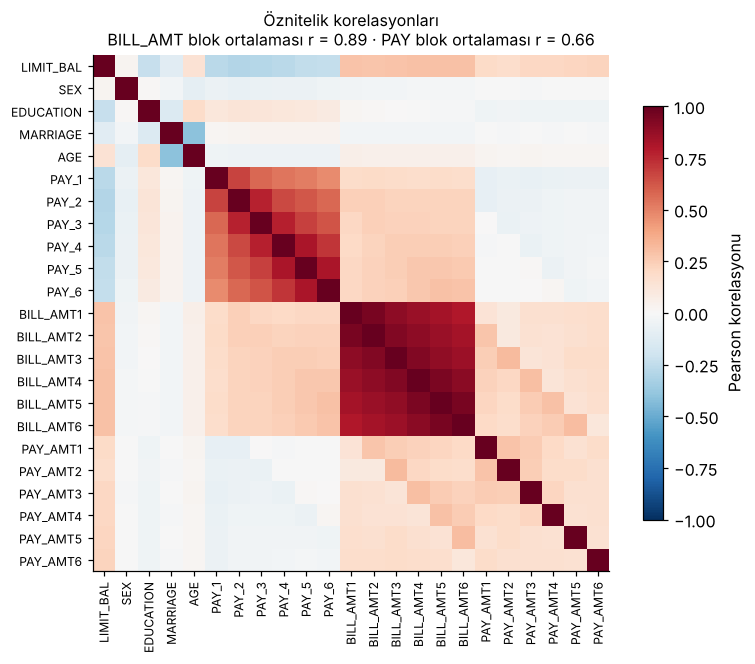

In [4]:
kor = X_df.corr().to_numpy()
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(d), OZN, rotation=90, fontsize=8)
ax.set_yticks(range(d), OZN, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson korelasyonu")
bill = [OZN.index(f"BILL_AMT{i}") for i in range(1, 7)]
pay = [OZN.index(f"PAY_{i}") for i in range(1, 7)]
ust = lambda idx: kor[np.ix_(idx, idx)][np.triu_indices(len(idx), 1)]
ax.set_title(f"Öznitelik korelasyonları\nBILL_AMT blok ortalaması r = {ust(bill).mean():.2f} · "
             f"PAY blok ortalaması r = {ust(pay).mean():.2f}", fontsize=10.5)
plt.tight_layout()
sekil_kaydet("01-korelasyon")
plt.show()

## 2. Modeller

Kara kutu olarak gradyan artırmalı ağaçları (GBM) kullanıyoruz. Tutarlılık deneyi için üç model daha eğitiyoruz: GBM'e yakın
başarımlı bir rastgele orman ve bir sinir ağı, karşılaştırma için de daha basit bir lojistik regresyon. Tüm modeller
standartlaştırılmış özniteliklerle çalışır; açıklamalar da bu ölçekte hesaplanır ve olasılık birimindedir.

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X_df.to_numpy(float), y, test_size=0.3, random_state=RS, stratify=y)
olcek = StandardScaler().fit(X_tr)
Xtr, Xte = olcek.transform(X_tr), olcek.transform(X_te)

modeller = {
    "GBM": GradientBoostingClassifier(n_estimators=150, max_depth=3, subsample=0.8, random_state=RS),
    "Rastgele orman": RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RS),
    "Sinir ağı": MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=300, random_state=RS),
    "Lojistik regresyon": LogisticRegression(max_iter=2000),
}
satirlar = []
for ad, m in modeller.items():
    t0 = time.perf_counter()
    m.fit(Xtr, y_tr)
    p = m.predict_proba(Xte)[:, 1]
    satirlar.append({"Model": ad, "Test AUC": roc_auc_score(y_te, p), "Doğruluk": accuracy_score(y_te, p > 0.5),
                     "Eğitim (sn)": time.perf_counter() - t0})
basarim = pd.DataFrame(satirlar).set_index("Model").round(3)
display(basarim)

kara_kutu = modeller["GBM"]
f = lambda X: kara_kutu.predict_proba(np.atleast_2d(X))[:, 1]

# Açıklanacak örnekler: test kümesinden sabit tohumla seçilir
idx = rng.choice(len(Xte), N_ORNEK, replace=False)
Xa = Xte[idx]

,Test AUC,Doğruluk,Eğitim (sn)
Model,,,
GBM,0.779,0.817,7.371
Rastgele orman,0.777,0.817,3.089
Sinir ağı,0.770,0.815,0.883
Lojistik regresyon,0.715,0.808,0.046


## 3. Açıklama yöntemleri ve yöntem özellikleri

> **Kitabın örneği:** Doğrusal regresyonun ağırlıklarını okuyan bir yöntem modelin içine bakar (yüksek yarı saydamlık); yalnızca
> girdiyi değiştirip tahmine bakan bir yöntem hiç bakmaz ama her modelde çalışır (yüksek taşınabilirlik). Açıklama üretmek
> darboğaz olduğunda algoritmik karmaşıklık belirleyici olur.
>
> **Bizim verimizde:** TreeSHAP ağacın içini okur; LIME ve KernelSHAP kara kutuya yalnızca dışarıdan bakar. Üçünün açıklama
> başına süresini ölçüyoruz.

Bölüm 32, açıklama *yöntemleri* için dört özellik sayar. İlk üçü yöntemin tasarımından gelir; dördüncüsünü ölçüyoruz.

| Yöntem | İfade gücü (çıktının dili) | Yarı saydamlık | Taşınabilirlik |
|---|---|---|---|
| LIME | Yerel doğrusal modelin ağırlıkları (eğim) | Yok: yalnızca girdi değiştirip tahmine bakar | Her model |
| KernelSHAP | Shapley değerleri (katkı, toplamı = tahmin − ortalama) | Yok | Her model |
| TreeSHAP | Shapley değerleri | Yüksek: ağaçların iç yapısını okur | Yalnızca ağaç modelleri |
| Vekil karar ağacı | EĞER-İSE kuralları | Yok | Her model |

In [6]:
arka_plan = shap.kmeans(Xtr, 25)                      # KernelSHAP için özetlenmiş arka plan
arka_plan_agac = shap.sample(Xtr, 100, random_state=RS)  # TreeSHAP (girişimsel) için arka plan
lime_ac = LimeTabularExplainer(Xtr, feature_names=OZN, mode="classification",
                               discretize_continuous=False, sample_around_instance=True, random_state=RS)


def lime_acikla(x, model=None, tohum=RS, ns=LIME_NS, k=None):
    """LIME: x çevresinde örnekler üretir, ağırlıklı doğrusal model kurar.
    Döndürür: ağırlık vektörü, yerel R², sabit terim, yerel modelin x'teki tahmini."""
    model = model or kara_kutu
    lime_ac.random_state = np.random.RandomState(tohum)
    e = lime_ac.explain_instance(x, model.predict_proba, num_features=k or d, num_samples=ns, labels=(1,))
    w = np.zeros(d)
    for j, v in e.as_map()[1]:
        w[j] = v
    return w, e.score, e.intercept[1], float(np.ravel(e.local_pred)[0])


def kshap_aciklayici(model):
    return shap.KernelExplainer(lambda X: model.predict_proba(X)[:, 1], arka_plan)


def kshap_acikla(aciklayici, X, tohum=RS, ns=KSHAP_NS):
    """KernelSHAP. l1_reg=False: shap'in varsayılan öznitelik seçimini kapatır, 23 özniteliğin hepsi için tahmin döner."""
    np.random.seed(tohum)  # KernelSHAP koalisyonları rastgele örnekler
    return np.atleast_2d(np.array(aciklayici.shap_values(np.atleast_2d(X), nsamples=ns, l1_reg=False, silent=True)))


ks_gbm = kshap_aciklayici(kara_kutu)
ts_gbm = shap.TreeExplainer(kara_kutu, data=arka_plan_agac, model_output="probability",
                            feature_perturbation="interventional")
tshap_acikla = lambda X: np.atleast_2d(ts_gbm.shap_values(np.atleast_2d(X)))

# Algoritmik karmaşıklık: açıklama başına süre
sure = {}
t0 = time.perf_counter(); A_lime = np.array([lime_acikla(x)[0] for x in Xa]); sure["LIME"] = (time.perf_counter() - t0) / N_ORNEK
t0 = time.perf_counter(); A_ks = kshap_acikla(ks_gbm, Xa); sure["KernelSHAP"] = (time.perf_counter() - t0) / N_ORNEK
t0 = time.perf_counter(); A_ts = tshap_acikla(Xa); sure["TreeSHAP"] = (time.perf_counter() - t0) / N_ORNEK
print("Açıklama başına süre (ms):", {k: round(1000 * v, 1) for k, v in sure.items()})

Açıklama başına süre (ms): {'LIME': 16.2, 'KernelSHAP': 65.6, 'TreeSHAP': 1.3}


**Aynı müşteri, üç açıklama.** Aşağıdaki grafik bölümün çıkış noktasını gösteriyor: Üç yöntem aynı tahmini açıklıyor ama
farklı şeyler söylüyor. Hangisinin "doğru" olduğunu söyleyecek bir temel gerçeklik yok. Bu yüzden özelliklerle değerlendirmemiz gerekiyor.

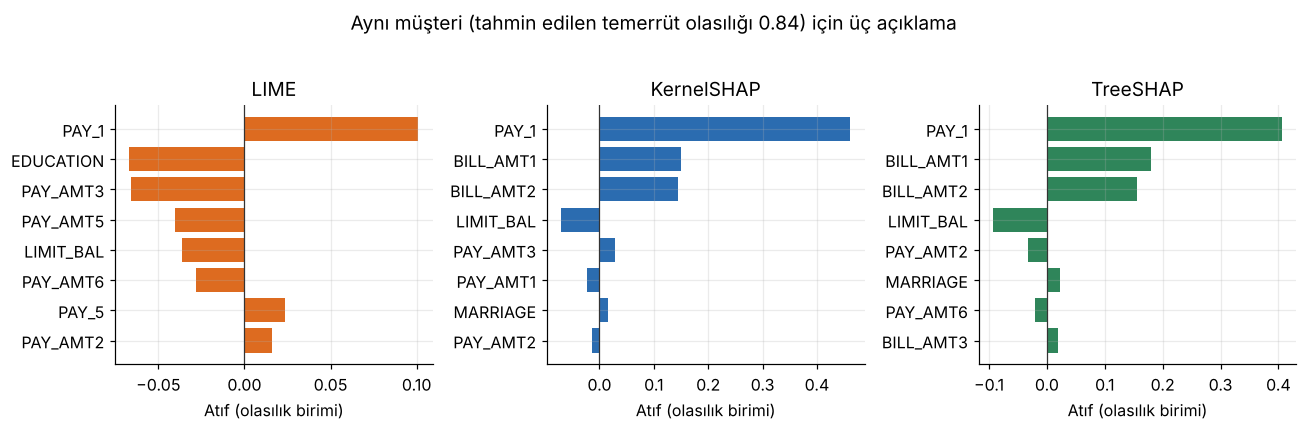

In [7]:
i0 = int(np.argmax(f(Xa)))  # açıklanan örnekler içinde temerrüt olasılığı en yüksek müşteri
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=False)
for ax, (ad, A) in zip(axes, [("LIME", A_lime), ("KernelSHAP", A_ks), ("TreeSHAP", A_ts)]):
    sira = np.argsort(-np.abs(A[i0]))[:8][::-1]
    ax.barh([OZN[j] for j in sira], A[i0, sira], color=RENK[ad])
    ax.axvline(0, color="#333", lw=0.8)
    ax.set_title(ad)
    ax.set_xlabel("Atıf (olasılık birimi)")
fig.suptitle(f"Aynı müşteri (tahmin edilen temerrüt olasılığı {f(Xa[i0])[0]:.2f}) için üç açıklama", y=1.02)
plt.tight_layout()
sekil_kaydet("02-ayni-musteri-uc-aciklama")
plt.show()

## 4. Doğruluk ve sadakat

> **Kitabın örneği:** Sadakat en önemli özelliklerden biridir; açıklama modelin yerine karar verecekse doğruluk da şarttır. LIME
> yalnızca bir bölgede, Shapley değerleri yalnızca tek bir örnekte sadıktır. Anlaşılabilirliğin vekil ölçütü açıklamanın
> boyutudur; işlev düzeyindeki örnekte ağacın derinliği kullanılır ve ağaç sığlaşırken doğruluk fazla düşmemelidir.
>
> **Bizim verimizde:** Küresel bir vekil ağacı 1'den 8'e kadar derinleştirip sadakatini ve doğruluğunu, LIME'ın da yerel
> sadakatini ölçüyoruz.

* **Sadakat:** Açıklama kara kutunun tahminine ne kadar iyi yaklaşıyor? Vekil ağaç için test kümesinde
  $R^2\big(f(x), g(x)\big)$, yani ağacın kara kutu olasılıklarını ne kadar iyi taklit ettiği.
* **Doğruluk:** Açıklama görülmemiş veriyi ne kadar iyi tahmin ediyor? Vekil ağacın **gerçek etiketlere** göre AUC'si.

Ağaç derinleştikçe sadakat artar ama yaprak sayısı, yani anlaşılabilirlik bedeli de büyür.

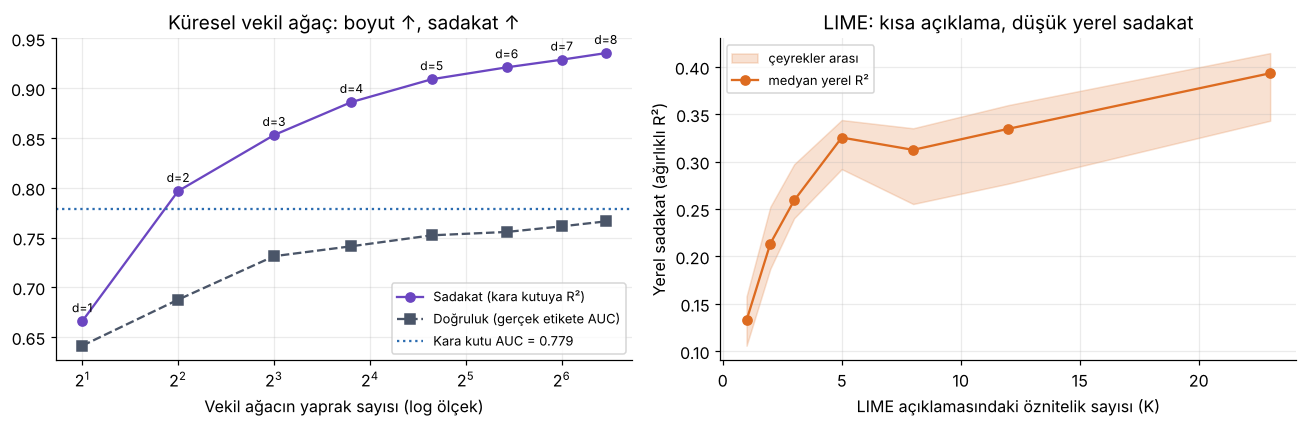

SHAP toplamsallığı (yerel doğruluk): en büyük hata TreeSHAP 1.4e-08, KernelSHAP 2.2e-16
LIME (tüm öznitelikler) medyan yerel R² = 0.39
LIME'ın yerel modelinin açıklanan müşterinin kendisindeki hatası |f(x) − g(x)|: medyan 0.173, en büyük 0.306 (olasılık birimi)
Derinlik 3 vekil ağacın kuralları:
|--- PAY_1 <= 1.35
|   |--- PAY_2 <= 1.36
|   |   |--- PAY_AMT3 <= -0.25
|   |   |   |--- value: [0.21]
|   |   |--- PAY_AMT3 >  -0.25
|   |   |   |--- value: [0.12]
|   |--- PAY_2 >  1.36
|   |   |--- PAY_6 <= 1.13
|   |   |   |--- value: [0.36]
|   |   |--- PAY_6 >  1.13
|   |   |   |--- value: [0.58]
|--- PAY_1 >  1.35
|   |--- PAY_3 <= -0.28
|   |   |--- BILL_AMT5 <= -0.66
|   |   |   |--- value: [0.60]
|   |   |--- BILL_AMT5 >  -0.66
|   |   |   |--- value: [0.41]
|   |--- PAY_3 >  -0.28
|   |   |--- PAY_5 <= 1.13
|   |   |   |--- value: [0.67]
|   |   |--- PAY_5 >  1.13
|   |   |   |--- value: [0.76]



In [8]:
f_tr, f_te = f(Xtr), f(Xte)
vekil = []
for derinlik in range(1, 9):
    g = DecisionTreeRegressor(max_depth=derinlik, min_samples_leaf=50, random_state=RS).fit(Xtr, f_tr)
    gp = g.predict(Xte)
    vekil.append({"Derinlik": derinlik, "Yaprak": g.get_n_leaves(), "Sadakat R²": r2_score(f_te, gp),
                  "Doğruluk AUC": roc_auc_score(y_te, gp)})
vekil = pd.DataFrame(vekil)
auc_kk = roc_auc_score(y_te, f_te)

# LIME'ın yerel sadakati: K öznitelikli açıklamanın yerel R²'si (anlaşılabilirlik ödünleşimi)
K_LISTE = [1, 2, 3, 5, 8, 12, d]
lime_k = {k: [lime_acikla(x, k=k)[1] for x in Xa[:N_KARARLILIK]] for k in K_LISTE}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(vekil["Yaprak"], vekil["Sadakat R²"], "o-", color=RENK["Vekil ağaç"], label="Sadakat (kara kutuya R²)")
a1.plot(vekil["Yaprak"], vekil["Doğruluk AUC"], "s--", color="#4A5568", label="Doğruluk (gerçek etikete AUC)")
a1.axhline(auc_kk, color="#2B6CB0", ls=":", label=f"Kara kutu AUC = {auc_kk:.3f}")
a1.set_xscale("log", base=2)
a1.set_xlabel("Vekil ağacın yaprak sayısı (log ölçek)")
a1.set_title("Küresel vekil ağaç: boyut ↑, sadakat ↑")
for _, r in vekil.iterrows():
    a1.annotate(f"d={int(r['Derinlik'])}", (r["Yaprak"], r["Sadakat R²"]), textcoords="offset points", xytext=(0, 6),
                ha="center", fontsize=8)
a1.legend(fontsize=8.5, loc="lower right")
ort = [np.median(lime_k[k]) for k in K_LISTE]
alt = [np.percentile(lime_k[k], 25) for k in K_LISTE]
ust_ = [np.percentile(lime_k[k], 75) for k in K_LISTE]
a2.fill_between(K_LISTE, alt, ust_, color=RENK["LIME"], alpha=0.2, label="çeyrekler arası")
a2.plot(K_LISTE, ort, "o-", color=RENK["LIME"], label="medyan yerel R²")
a2.set_xlabel("LIME açıklamasındaki öznitelik sayısı (K)")
a2.set_ylabel("Yerel sadakat (ağırlıklı R²)")
a2.set_title("LIME: kısa açıklama, düşük yerel sadakat")
a2.legend(fontsize=8.5)
plt.tight_layout()
sekil_kaydet("03-sadakat-anlasilabilirlik")
plt.show()

hata_ts = np.abs(A_ts.sum(1) + ts_gbm.expected_value - f(Xa)).max()
hata_ks = np.abs(A_ks.sum(1) + ks_gbm.expected_value - f(Xa)).max()
lime_x_hatasi = np.array([abs(lime_acikla(x)[3] - f(x)[0]) for x in Xa])
print(f"SHAP toplamsallığı (yerel doğruluk): en büyük hata TreeSHAP {hata_ts:.1e}, KernelSHAP {hata_ks:.1e}")
print(f"LIME (tüm öznitelikler) medyan yerel R² = {np.median(lime_k[d]):.2f}")
print(f"LIME'ın yerel modelinin açıklanan müşterinin kendisindeki hatası |f(x) − g(x)|: "
      f"medyan {np.median(lime_x_hatasi):.3f}, en büyük {lime_x_hatasi.max():.3f} (olasılık birimi)")
print("Derinlik 3 vekil ağacın kuralları:\n" + export_text(
    DecisionTreeRegressor(max_depth=3, min_samples_leaf=50, random_state=RS).fit(Xtr, f_tr), feature_names=OZN, decimals=2))

**Yorum.** Bu veri setinde kara kutu büyük ölçüde son ayın ödeme durumuna (`PAY_1`) dayandığı için, derinliği 3 olan (8 yapraklı)
bir ağaç bile davranışın büyük kısmını okunabilir kurallarla yakalıyor. Ağaç büyüdükçe sadakat artıyor ama kuralları okumak zorlaşıyor.
SHAP yöntemleri tanım gereği toplamsaldır, yani atıfların toplamı tahmine eşittir. Bu, sadakatin *bir* biçimidir ama açıklamanın
modelin "neden" öyle karar verdiğini doğru yakaladığını garanti etmez.

LIME'da durum daha çarpıcı: Yerel modelin R²'si düşük. Dahası, açıklanan müşterinin **kendisi için** verdiği tahmin bile kara kutudan
belirgin biçimde sapıyor. Nedeni boyut sayısı: LIME her öznitelikte bir standart sapmalık gürültüyle örnek üretir. 23 boyutta bu
örnekler müşteriden ortalama $\sqrt{23} \approx 4{,}8$ standart sapma uzağa düşer. Varsayılan çekirdek genişliği
($0{,}75\sqrt{23} \approx 3{,}6$) bu uzak örnekleri neredeyse eşit ağırlıklandırır. Sonuçta "yerel" model, müşterinin çevresini değil
geniş ve gerçekte olmayan bir bölgeyi özetler.

## 5. Kararlılık

> **Kitabın örneği:** Birbirine çok benzeyen iki örneğe, tahmin de pek değişmiyorsa, çok farklı açıklama verilmemeli.
> Kararsızlığın kaynakları yöntemin yüksek varyansı ve LIME'ın örnekleme adımı gibi rastgele bileşenlerdir.
>
> **Bizim verimizde:** Aynı müşteriyi farklı tohumlarla ve çok az değiştirilmiş komşularıyla açıklıyoruz.

**(a) Tekrar kararlılığı:** Aynı örneği aynı yöntemle farklı rastgele tohumlarla açıklarız ve en önemli 5 özniteliğin
kümeleri arasındaki ortalama Jaccard benzerliğine bakarız ($|A\cap B|/|A\cup B|$, 1 = hep aynı). Bölüm, deterministik olmayan
bileşenleri (LIME'ın örneklemesi gibi) kararsızlığın bir kaynağı olarak sayar.

**(b) Girdi kararlılığı:** Bölümün tanımıyla, bir örneğin özniteliklerindeki küçük değişiklikler açıklamayı önemli ölçüde
değiştirmemelidir. Müşteriyi çok az değiştirerek komşular üretiriz (her öznitelikte $\epsilon \sim N(0,\,0{,}05^2)$ standart sapma)
ve açıklamanın ilk 5 özniteliğinin ne kadar aynı kaldığını yine Jaccard@5 ile ölçeriz. LIME ve KernelSHAP'ta tohumu sabit tutarız;
böylece fark yalnızca girdideki değişimden gelir. Karşılaştırma için modelin tahminindeki değişimi de raporlarız: Tahmin neredeyse
hiç değişmiyorsa açıklamanın da değişmemesi beklenir.

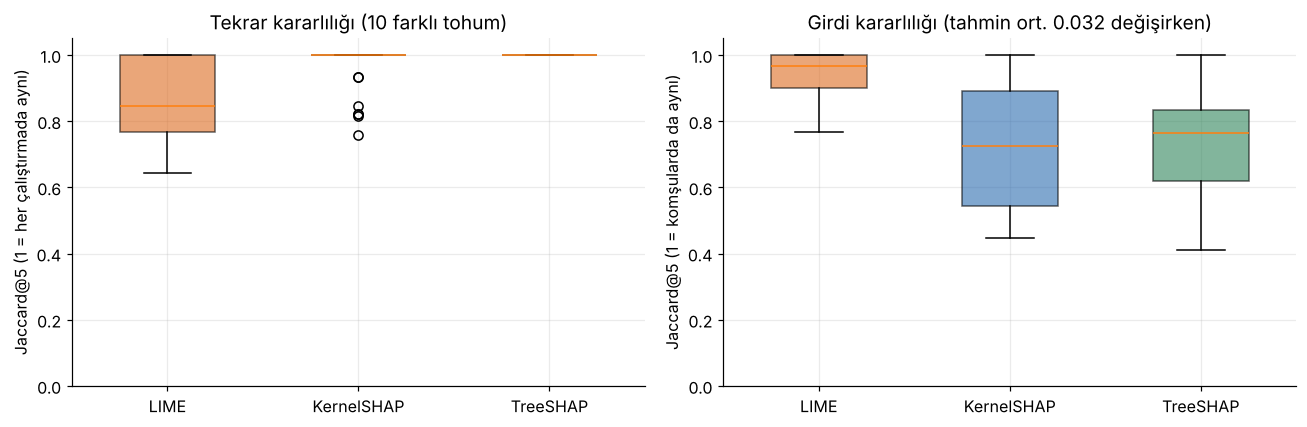

Medyan Jaccard@5, tekrar: {'LIME': 0.84, 'KernelSHAP': 1.0, 'TreeSHAP': 1.0}
Medyan Jaccard@5, girdi : {'LIME': 0.97, 'KernelSHAP': 0.72, 'TreeSHAP': 0.76}
Komşularda tahmin edilen olasılığın ortalama mutlak değişimi: 0.0323


In [9]:
def jaccard_top(A, k=5):
    kume = [set(np.argsort(-np.abs(a))[:k]) for a in A]
    return np.mean([len(kume[i] & kume[j]) / len(kume[i] | kume[j])
                    for i in range(len(kume)) for j in range(i + 1, len(kume))])


Xk = Xa[:N_KARARLILIK]
tekrar = {"LIME": [], "KernelSHAP": [], "TreeSHAP": []}
for x in Xk:
    tekrar["LIME"].append(jaccard_top([lime_acikla(x, tohum=t)[0] for t in range(N_TEKRAR)]))
    tekrar["KernelSHAP"].append(jaccard_top([kshap_acikla(ks_gbm, x, tohum=t)[0] for t in range(N_TEKRAR)]))
    tekrar["TreeSHAP"].append(jaccard_top([tshap_acikla(x)[0] for _ in range(2)]))

def jaccard_cift(a, b, k=5):
    A, B = set(np.argsort(-np.abs(a))[:k]), set(np.argsort(-np.abs(b))[:k])
    return len(A & B) / len(A | B)


girdi = {"LIME": [], "KernelSHAP": [], "TreeSHAP": []}
tahmin_degisimi = []
for x in Xk:
    komsular = x + rng.normal(0, 0.05, size=(N_KOMSU, d))
    e0 = {"LIME": lime_acikla(x)[0], "KernelSHAP": kshap_acikla(ks_gbm, x)[0], "TreeSHAP": tshap_acikla(x)[0]}
    E = {"LIME": np.array([lime_acikla(z)[0] for z in komsular]),
         "KernelSHAP": kshap_acikla(ks_gbm, komsular), "TreeSHAP": tshap_acikla(komsular)}
    for ad in girdi:
        girdi[ad].append(np.mean([jaccard_cift(e0[ad], e) for e in E[ad]]))
    tahmin_degisimi.append(np.mean(np.abs(f(komsular) - f(x))))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
b = a1.boxplot([tekrar[k] for k in tekrar], patch_artist=True, widths=0.5)
a1.set_xticks(range(1, len(tekrar) + 1), list(tekrar))
for kutu, ad in zip(b["boxes"], tekrar):
    kutu.set_facecolor(RENK[ad]); kutu.set_alpha(0.6)
a1.set_ylim(0, 1.05)
a1.set_ylabel("Jaccard@5 (1 = her çalıştırmada aynı)")
a1.set_title(f"Tekrar kararlılığı ({N_TEKRAR} farklı tohum)")
ad3 = list(girdi)
b = a2.boxplot([girdi[k] for k in ad3], patch_artist=True, widths=0.5)
a2.set_xticks(range(1, 4), ad3)
for kutu, ad in zip(b["boxes"], ad3):
    kutu.set_facecolor(RENK[ad]); kutu.set_alpha(0.6)
a2.set_ylim(0, 1.05)
a2.set_ylabel("Jaccard@5 (1 = komşularda da aynı)")
a2.set_title(f"Girdi kararlılığı (tahmin ort. {np.mean(tahmin_degisimi):.3f} değişirken)")
plt.tight_layout()
sekil_kaydet("04-kararlilik")
plt.show()
print("Medyan Jaccard@5, tekrar:", {k: round(float(np.median(v)), 2) for k, v in tekrar.items()})
print("Medyan Jaccard@5, girdi :", {k: round(float(np.median(v)), 2) for k, v in girdi.items()})
print(f"Komşularda tahmin edilen olasılığın ortalama mutlak değişimi: {np.mean(tahmin_degisimi):.4f}")

**Yorum.** TreeSHAP deterministiktir; aynı girdiye her zaman aynı açıklamayı verir. LIME'ın ve sınırlı sayıda koalisyon
örnekleyen KernelSHAP'ın sonucu ise tohuma bağlıdır. Girdi kararlılığında modelin tahmini neredeyse hiç değişmezken
açıklamanın ilk 5'i değişiyorsa, kararsızlık modelden değil açıklama yönteminden gelir. İki kararlılık türü farklı şeyler ölçer:
Bir yöntem tohuma karşı kararlı, girdiye karşı kararsız olabilir; bunun tersi de mümkündür.

## 6. Tutarlılık: Rashomon etkisi

> **Kitabın örneği:** Aynı görevde bir SVM ve bir doğrusal regresyon eğitilir; ikisi de birbirine çok yakın tahminler üretir.
> Aynı yöntemle açıklandıklarında açıklamaları da benziyor mu? Kitap uyarıyor: İki model aynı tahmine farklı özniteliklerle
> varabilir (Rashomon etkisi); o zaman açıklamaların farklı olması doğrudur.
>
> **Bizim verimizde:** Önce kitabın örneğini birebir kuruyoruz (6a), sonra aynı soruyu dört modelle soruyoruz (6b).

### 6a. Kitabın örneği birebir: SVM ile lojistik regresyon

Sınıflandırmada doğrusal regresyonun karşılığı lojistik regresyondur. SVM'i, süre kısa kalsın diye eğitim kümesinden rastgele
seçilmiş bir alt kümede eğitiyoruz. İki modeli aynı müşteriler için aynı yöntemle (KernelSHAP, aynı arka plan) açıklıyoruz.
Örnek müşteri olarak, iki modelin tahmini birbirine en yakın müşteriler arasından açıklamaları en az benzeyeni gösteriyoruz;
genel tabloyu ise grafiğin altındaki medyanlar veriyor.

Test AUC: SVM 0.725 · lojistik regresyon 0.715 · tahminler arası korelasyon r = 0.80


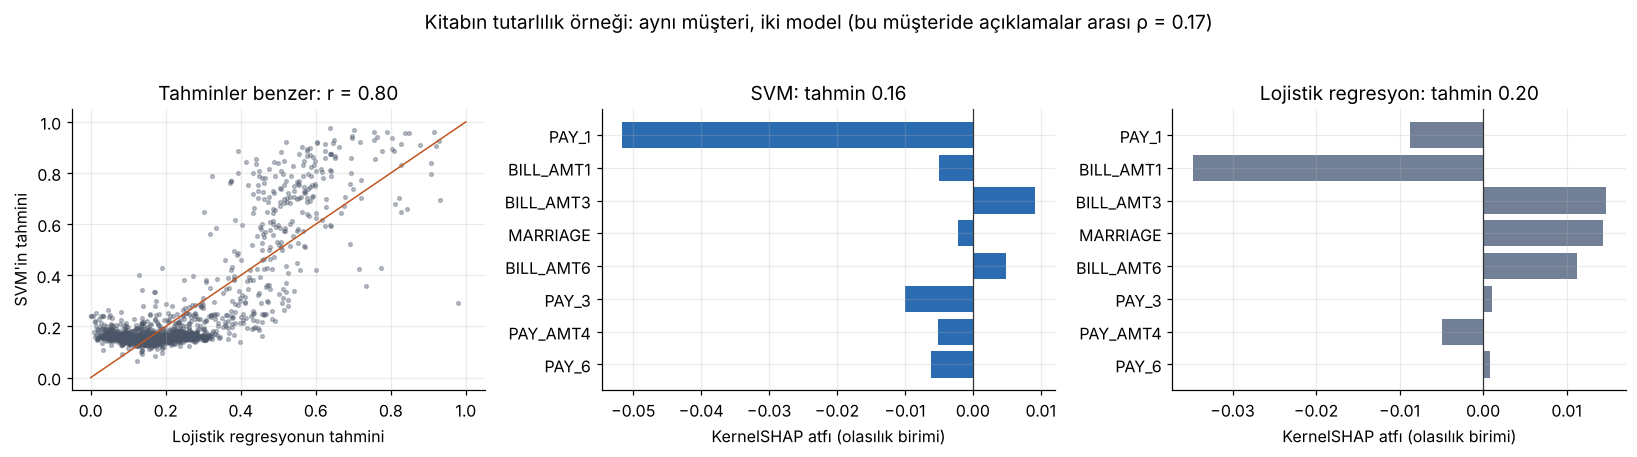

40 müşteride iki açıklama arasındaki medyan Spearman ρ = 0.34, medyan Jaccard@5 = 0.43


In [10]:
from sklearn.svm import SVC

rng_ek = np.random.default_rng(RS + 1)  # ek örnekler ayrı üreteçle: diğer bölümlerin sonuçları değişmesin
alt_kume = rng_ek.choice(len(Xtr), 1500 if HIZLI else 3000, replace=False)
svm = SVC(C=1.0, gamma="scale", probability=True, random_state=RS).fit(Xtr[alt_kume], y_tr[alt_kume])
lojistik = modeller["Lojistik regresyon"]
p_svm, p_loj = svm.predict_proba(Xte)[:, 1], lojistik.predict_proba(Xte)[:, 1]
r_sl = np.corrcoef(p_svm, p_loj)[0, 1]
print(f"Test AUC: SVM {roc_auc_score(y_te, p_svm):.3f} · lojistik regresyon {roc_auc_score(y_te, p_loj):.3f} · "
      f"tahminler arası korelasyon r = {r_sl:.2f}")

N_SVM = 15 if HIZLI else 40
Xs = Xa[:N_SVM]
A_svm = kshap_acikla(kshap_aciklayici(svm), Xs)
A_loj = kshap_acikla(kshap_aciklayici(lojistik), Xs)
rho_sl = np.array([spearmanr(a, b)[0] for a, b in zip(A_svm, A_loj)])
jac_sl = np.array([jaccard_cift(a, b) for a, b in zip(A_svm, A_loj)])
fark_p = np.abs(svm.predict_proba(Xs)[:, 1] - lojistik.predict_proba(Xs)[:, 1])
adaylar = np.argsort(fark_p)[: max(5, N_SVM // 4)]
i_sl = int(adaylar[np.argmin(rho_sl[adaylar])])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
sec = rng_ek.choice(len(Xte), 2000, replace=False)
axes[0].scatter(p_loj[sec], p_svm[sec], s=6, alpha=0.35, color="#4A5568")
axes[0].plot([0, 1], [0, 1], color="#C05621", lw=1)
axes[0].set_xlabel("Lojistik regresyonun tahmini")
axes[0].set_ylabel("SVM'in tahmini")
axes[0].set_title(f"Tahminler benzer: r = {r_sl:.2f}")
ust8 = np.argsort(-(np.abs(A_svm[i_sl]) + np.abs(A_loj[i_sl])))[:8][::-1]
for ax, A, ad, renk, model_ in [(axes[1], A_svm, "SVM", "#2B6CB0", svm),
                                (axes[2], A_loj, "Lojistik regresyon", "#718096", lojistik)]:
    ax.barh([OZN[j] for j in ust8], A[i_sl, ust8], color=renk)
    ax.axvline(0, color="#333", lw=0.8)
    ax.set_title(f"{ad}: tahmin {model_.predict_proba(Xs[i_sl:i_sl + 1])[0, 1]:.2f}")
    ax.set_xlabel("KernelSHAP atfı (olasılık birimi)")
plt.suptitle(f"Kitabın tutarlılık örneği: aynı müşteri, iki model (bu müşteride açıklamalar arası ρ = {rho_sl[i_sl]:.2f})", y=1.03)
plt.tight_layout()
sekil_kaydet("05a-kitap-ornegi-svm-lojistik")
plt.show()
print(f"{N_SVM} müşteride iki açıklama arasındaki medyan Spearman ρ = {np.median(rho_sl):.2f}, "
      f"medyan Jaccard@5 = {np.median(jac_sl):.2f}")

**Yorum (6a).** İki model test kümesinde birbirine yakın tahminler üretiyor (r = 0,80; AUC 0,725 ve 0,715). Yine de aynı yöntemle
(KernelSHAP) hesaplanan açıklamaları zayıf örtüşüyor: 40 müşteride açıklamalar arası medyan Spearman ρ = 0,34, en önemli 5
özniteliğin ortaklığı (Jaccard@5) 0,43. Grafikteki müşteride (ρ = 0,18) SVM'in açıklamasında ödeme durumları (`PAY_1`, `PAY_3`),
lojistik regresyonunkinde fatura tutarları (`BILL_AMT1`, `BILL_AMT3`) öne çıkıyor. Kitabın uyarısı burada geçerli: Tahminler
benzer olsa da iki model aynı sonuca farklı özniteliklerle varabiliyor. Bu yüzden düşük tutarlılık tek başına açıklama
yönteminin hatası sayılmaz; modellerin gerçekten farklı ilişkilere dayandığını da gösterebilir.

### 6b. Dört modelle Rashomon etkisi

Aynı görevde eğitilmiş, benzer tahminler üreten modellerin açıklamaları ne kadar benzer? Tüm modelleri **aynı yöntemle**
(KernelSHAP, aynı arka plan) açıklarız. Böylece fark yöntemden değil modellerden gelir. Solda modellerin tahminleri arasındaki
korelasyon, sağda açıklamaları arasındaki ortalama Spearman sıra korelasyonu yer alıyor.

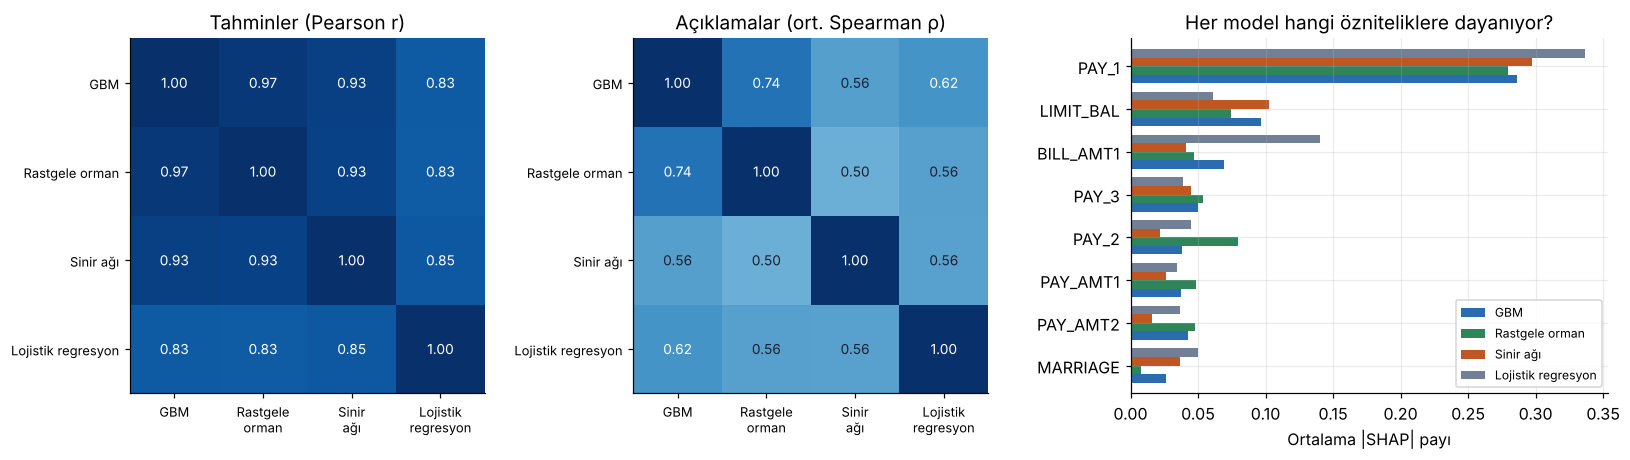

Tahminler arası korelasyon: 0.83–0.97 · açıklamalar arası sıra korelasyonu: 0.50–0.74


In [11]:
adlar = list(modeller)
A_model = {ad: (A_ks if ad == "GBM" else kshap_acikla(kshap_aciklayici(modeller[ad]), Xa)) for ad in adlar}
P = {ad: modeller[ad].predict_proba(Xte)[:, 1] for ad in adlar}
M = len(adlar)
tahmin_kor, aciklama_kor = np.eye(M), np.eye(M)
for i in range(M):
    for j in range(i + 1, M):
        tahmin_kor[i, j] = tahmin_kor[j, i] = np.corrcoef(P[adlar[i]], P[adlar[j]])[0, 1]
        rho = [spearmanr(a, b)[0] for a, b in zip(A_model[adlar[i]], A_model[adlar[j]])]
        aciklama_kor[i, j] = aciklama_kor[j, i] = np.nanmean(rho)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1, 1, 1.3]})
for ax, Mx, baslik in [(axes[0], tahmin_kor, "Tahminler (Pearson r)"), (axes[1], aciklama_kor, "Açıklamalar (ort. Spearman ρ)")]:
    ax.imshow(Mx, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(M), [a.replace(" ", "\n") for a in adlar], fontsize=8.5)
    ax.set_yticks(range(M), adlar, fontsize=8.5)
    ax.grid(False)
    for i in range(M):
        for j in range(M):
            ax.text(j, i, f"{Mx[i, j]:.2f}", ha="center", va="center", color="white" if Mx[i, j] > 0.6 else "#1A202C", fontsize=9)
    ax.set_title(baslik)
onem = pd.DataFrame({ad: np.abs(A_model[ad]).mean(0) for ad in adlar}, index=OZN)
onem = onem / onem.sum()
ilk = onem.mean(1).sort_values(ascending=False).index[:8]
onem.loc[ilk[::-1]].plot.barh(ax=axes[2], width=0.8, color=["#2B6CB0", "#2F855A", "#C05621", "#718096"])
axes[2].set_xlabel("Ortalama |SHAP| payı")
axes[2].set_title("Her model hangi özniteliklere dayanıyor?")
axes[2].legend(fontsize=8)
plt.tight_layout()
sekil_kaydet("05-tutarlilik-rashomon")
plt.show()
ust_ucgen = np.triu_indices(M, 1)
print(f"Tahminler arası korelasyon: {tahmin_kor[ust_ucgen].min():.2f}–{tahmin_kor[ust_ucgen].max():.2f} · "
      f"açıklamalar arası sıra korelasyonu: {aciklama_kor[ust_ucgen].min():.2f}–{aciklama_kor[ust_ucgen].max():.2f}")

**Yorum.** Tahminler birbirine yakın olsa da açıklamalar daha az örtüşür. Bölümün uyardığı gibi yüksek tutarlılık ancak modeller
gerçekten aynı ilişkilere dayanıyorsa beklenir. Çoklu bağlantılı `PAY` ve `BILL_AMT` blokları, aynı bilginin modeller arasında farklı
özniteliklere dağıtılmasına izin verir; sağdaki grafikte rastgele ormanın `PAY_2`'ye, lojistik regresyonun `BILL_AMT1`'e daha çok
dayandığı görülüyor. KernelSHAP'ın tekrar kararlılığı yüksek olduğundan (bölüm 5), farkın büyük kısmı yöntemin gürültüsünden değil
modellerin kendisinden geliyor. Yani buradaki düşük tutarlılık açıklamanın hatası değil, Rashomon etkisinin bir göstergesi.

## 7. Belirlilik

> **Kitabın örneği:** Model iki farklı hastaya da %4 kanser riski veriyor. İkisinden de aynı derecede emin mi? Açıklamanın
> kendisi de veriden yapılmış bir tahmindir; onun da belirsizliği vardır.
>
> **Bizim verimizde:** Önce bütün açıklanan müşterilerde model belirsizliğini açıklama belirsizliğiyle karşılaştırıyoruz, sonra
> kitabın örneğini birebir kuruyoruz (7a): aynı olasılığı alan iki müşteri.

Açıklama, modelin ne kadar emin olduğunu yansıtıyor mu? Modelin belirsizliğini, eğitim verisinden bootstrap ile üretilmiş
$B$ GBM'in tahminlerinin standart sapmasıyla ölçüyoruz. Her modelde TreeSHAP açıklamalarını da hesaplıyoruz; açıklamanın
belirsizliği, atıfların modeller arasındaki standart sapmasının ortalamasıdır.

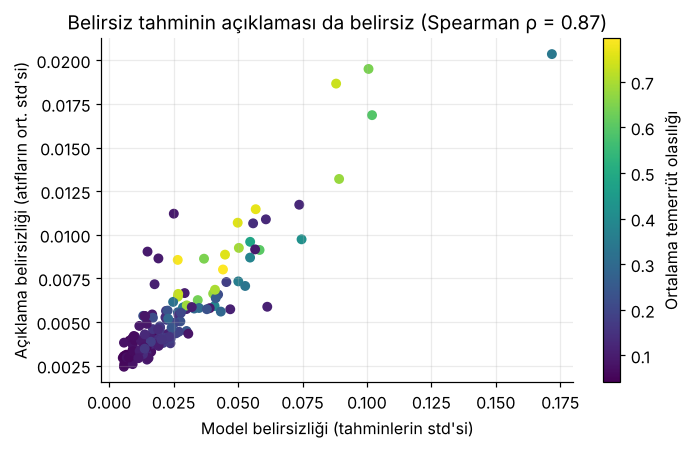

In [12]:
boot_modeller = []
for b in range(B_BOOT):
    s = rng.choice(len(Xtr), len(Xtr), replace=True)
    boot_modeller.append(GradientBoostingClassifier(n_estimators=100, max_depth=3, subsample=0.8, random_state=b).fit(Xtr[s], y_tr[s]))
boot_tahmin = np.array([m.predict_proba(Xa)[:, 1] for m in boot_modeller])
boot_aciklama = np.array([shap.TreeExplainer(m, data=arka_plan_agac, model_output="probability",
                                             feature_perturbation="interventional").shap_values(Xa) for m in boot_modeller])
model_belirsizligi = boot_tahmin.std(0)
aciklama_belirsizligi = boot_aciklama.std(0).mean(1)
rho_b = spearmanr(model_belirsizligi, aciklama_belirsizligi)[0]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sc_ = ax.scatter(model_belirsizligi, aciklama_belirsizligi, c=boot_tahmin.mean(0), cmap="viridis", s=30)
fig.colorbar(sc_, ax=ax, label="Ortalama temerrüt olasılığı")
ax.set_xlabel("Model belirsizliği (tahminlerin std'si)")
ax.set_ylabel("Açıklama belirsizliği (atıfların ort. std'si)")
ax.set_title(f"Belirsiz tahminin açıklaması da belirsiz (Spearman ρ = {rho_b:.2f})")
plt.tight_layout()
sekil_kaydet("06-belirlilik")
plt.show()

### 7a. Kitabın örneği birebir: aynı olasılık, farklı güven

Ana modelin (GBM) neredeyse aynı temerrüt olasılığını verdiği iki müşteri seçiyoruz: Biri için bootstrap modelleri hemfikir,
öteki için dağınık. Solda her nokta bir bootstrap modelinin tahmini; sağda iki müşterinin açıklaması ve bu açıklamanın bootstrap
modelleri arasında ne kadar oynadığı (hata çubukları) var.

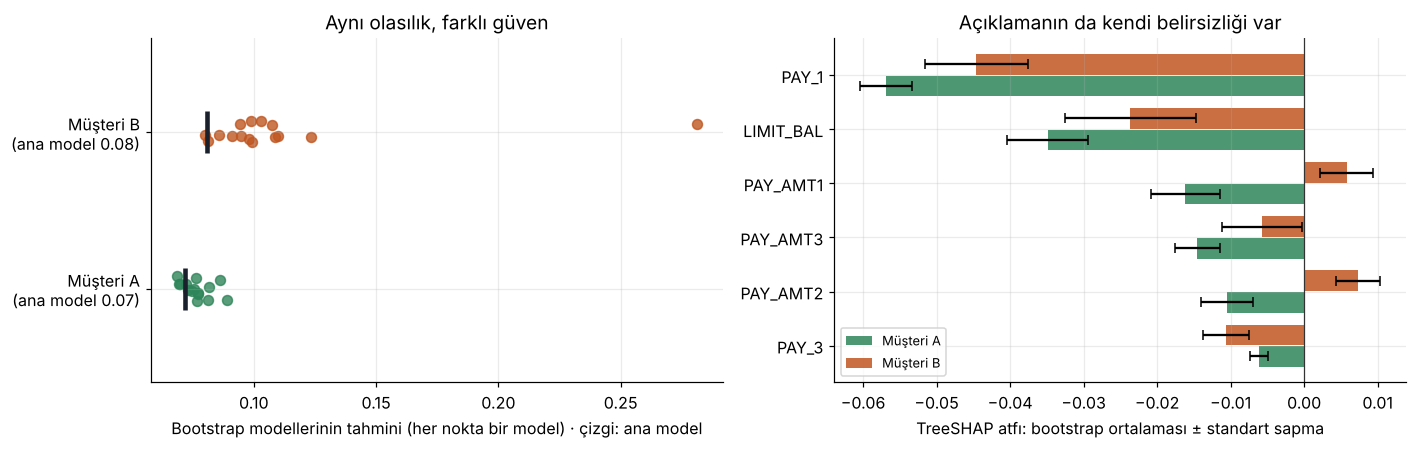

Müşteri A: ana model 0.072 · bootstrap tahminlerinin std'si 0.006 · açıklama belirsizliği 0.0038
Müşteri B: ana model 0.081 · bootstrap tahminlerinin std'si 0.047 · açıklama belirsizliği 0.0057


In [13]:
p_ana = f(Xa)
en_iyi = (0.0, 0, 1)
for i in range(len(Xa)):
    for j in range(len(Xa)):
        if i != j and abs(p_ana[i] - p_ana[j]) < 0.01 and model_belirsizligi[j] > model_belirsizligi[i] > 0:
            oran = model_belirsizligi[j] / model_belirsizligi[i]
            if oran > en_iyi[0]:
                en_iyi = (oran, i, j)
_, iA, iB = en_iyi

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
for k, (ii, renk) in enumerate([(iA, "#2F855A"), (iB, "#C05621")]):
    a1.scatter(boot_tahmin[:, ii], k + rng_ek.uniform(-0.08, 0.08, B_BOOT), color=renk, s=42, alpha=0.8)
    a1.plot(p_ana[ii], k, marker="|", ms=28, mew=3, color="#1A202C")
a1.set_yticks([0, 1], [f"Müşteri A\n(ana model {p_ana[iA]:.2f})", f"Müşteri B\n(ana model {p_ana[iB]:.2f})"])
a1.set_ylim(-0.6, 1.6)
a1.set_xlabel("Bootstrap modellerinin tahmini (her nokta bir model) · çizgi: ana model")
a1.set_title("Aynı olasılık, farklı güven")
ust6 = np.argsort(-(np.abs(boot_aciklama[:, iA].mean(0)) + np.abs(boot_aciklama[:, iB].mean(0))))[:6][::-1]
y_ = np.arange(len(ust6))
for ii, renk, kay, ad in [(iA, "#2F855A", -0.2, "Müşteri A"), (iB, "#C05621", 0.2, "Müşteri B")]:
    a2.barh(y_ + kay, boot_aciklama[:, ii, ust6].mean(0), height=0.38, xerr=boot_aciklama[:, ii, ust6].std(0),
            color=renk, alpha=0.85, label=ad, capsize=3)
a2.set_yticks(y_, [OZN[j] for j in ust6])
a2.axvline(0, color="#333", lw=0.8)
a2.set_xlabel("TreeSHAP atfı: bootstrap ortalaması ± standart sapma")
a2.set_title("Açıklamanın da kendi belirsizliği var")
a2.legend(fontsize=8.5)
plt.tight_layout()
sekil_kaydet("06a-kitap-ornegi-ayni-olasilik")
plt.show()
for ad, ii in [("A", iA), ("B", iB)]:
    print(f"Müşteri {ad}: ana model {p_ana[ii]:.3f} · bootstrap tahminlerinin std'si {model_belirsizligi[ii]:.3f} · "
          f"açıklama belirsizliği {aciklama_belirsizligi[ii]:.4f}")

**Yorum.** Tek bir SHAP grafiği bu belirsizliği göstermez; aynı müşteri için tek bir çubuk dizisi verir. Bölümün önerdiği gibi açıklama,
modelin ve kendisinin belirsizliğini de taşımalıdır; örneğin bootstrap aralıklarıyla. Bu iki müşteride ana model
neredeyse aynı olasılığı veriyor (A: 0,072; B: 0,081). Bootstrap modelleri ise A için hemfikir (standart sapma 0,006), B için
dağınık (0,047; tahminler 0,08 ile 0,28 arasında). Aynı olasılığın arkasındaki güven yaklaşık sekiz kat farklı: Kitaptaki %4
kanser olasılığı örneğinin verimizdeki karşılığı budur. B'nin açıklaması da daha oynak; atıfların bootstrap modelleri
arasındaki ortalama standart sapması A'da 0,0038, B'de 0,0057.

## 8. Önem derecesi

> **Kitabın örneği:** Açıklama bir karar kuralıysa, kuralın hangi koşulunun en önemli olduğu belli mi?
>
> **Bizim verimizde:** Atıf yöntemlerinde ağırlığın en önemli 3 öznitelikte ne kadar toplandığını ölçüyor, vekil ağacın en
> riskli dalındaki kuralı gerçek birimleriyle yazdırıyor, sonra kuralın koşullarını tek tek kaldırarak hangisinin belirleyici
> olduğunu ölçüyoruz.

Açıklama, hangi öznitelik ya da koşulun en önemli olduğunu açıkça gösteriyor mu? Atıf yöntemleri öznitelikleri sıralar. Bir
açıklamanın ağırlığının ne kadarının en önemli 3 öznitelikte toplandığını ölçüyoruz. Vekil ağacın bir yaprağa giden kural yolu
ise koşulları sıralamaz; bu da önem derecesinin açıklamanın *biçimine* bağlı olduğunu gösterir.

In [14]:
pay3 = lambda A: np.sort(np.abs(A), 1)[:, ::-1][:, :3].sum(1) / (np.abs(A).sum(1) + 1e-12)
onem_derecesi = {"LIME": pay3(A_lime), "KernelSHAP": pay3(A_ks), "TreeSHAP": pay3(A_ts)}
print("En önemli 3 özniteliğin toplam |atıf| içindeki medyan payı:",
      {k: f"%{100 * np.median(v):.0f}" for k, v in onem_derecesi.items()})

# Vekil ağacın (derinlik 3) en riskli dalı: eşikleri standart birimden özgün birime çeviriyoruz
agac3 = DecisionTreeRegressor(max_depth=3, min_samples_leaf=50, random_state=RS).fit(Xtr, f_tr).tree_
yapraklar = np.where(agac3.children_left == -1)[0]
en_riskli = int(yapraklar[np.argmax(agac3.value[yapraklar].ravel())])
ebeveyn = {int(c): (n, "≤") for n, c in enumerate(agac3.children_left) if c != -1}
ebeveyn.update({int(c): (n, ">") for n, c in enumerate(agac3.children_right) if c != -1})
kosullar, yol, dugum = [], [], en_riskli
while dugum in ebeveyn:
    ust_dugum, yon = ebeveyn[dugum]
    j = agac3.feature[ust_dugum]
    kosullar.append(f"{OZN[j]} {yon} {olcek.mean_[j] + agac3.threshold[ust_dugum] * olcek.scale_[j]:.2f}")
    yol.append((j, yon, agac3.threshold[ust_dugum]))
    dugum = ust_dugum
kosullar, yol = kosullar[::-1], yol[::-1]
kural_tahmini = float(agac3.value[en_riskli].ravel()[0])
print("Vekil ağacın en riskli dalı (eşikler özgün birimde):\n  EĞER " + "\n  VE ".join(kosullar)
      + f"\n  İSE vekil ağacın tahmini {kural_tahmini:.2f}\nKural, koşullardan hangisinin belirleyici olduğunu söylemiyor.")


def kural_maskesi(haric=None):
    """Kuralın koşullarını (haric numaralı koşul dışında) sağlayan eğitim örnekleri."""
    m = np.ones(len(Xtr), bool)
    for k, (j, yon, esik) in enumerate(yol):
        if k != haric:
            m &= (Xtr[:, j] <= esik) if yon == "≤" else (Xtr[:, j] > esik)
    return m


# Kural koşulları kendi aralarında sıralanmaz; sıralamayı ayrıca ölçmek gerekir. Her koşulu sırayla kaldırıp kuralın kapsadığı
# müşteri sayısına ve bu müşterilerde kara kutunun ortalama tahminine bakıyoruz: Kaldırıldığında riski en çok düşüren koşul,
# bu kural için en belirleyici olandır.
kosul_onemi = pd.DataFrame(
    [{"Kaldırılan koşul": "(hiçbiri: tam kural)", "Kapsanan müşteri": int(kural_maskesi().sum()),
      "Ortalama tahmin": f_tr[kural_maskesi()].mean()}]
    + [{"Kaldırılan koşul": kosul, "Kapsanan müşteri": int(kural_maskesi(k).sum()), "Ortalama tahmin": f_tr[kural_maskesi(k)].mean()}
       for k, kosul in enumerate(kosullar)]).round(3)
display(kosul_onemi)

En önemli 3 özniteliğin toplam |atıf| içindeki medyan payı: {'LIME': '%42', 'KernelSHAP': '%53', 'TreeSHAP': '%46'}
Vekil ağacın en riskli dalı (eşikler özgün birimde):
  EĞER PAY_1 > 1.50
  VE PAY_3 > -0.50
  VE PAY_5 > 1.00
  İSE vekil ağacın tahmini 0.76
Kural, koşullardan hangisinin belirleyici olduğunu söylemiyor.


,Kaldırılan koşul,Kapsanan müşteri,Ortalama tahmin
0,(hiçbiri: tam kural),897,0.759
1,PAY_1 > 1.50,1960,0.578
2,PAY_3 > -0.50,902,0.757
3,PAY_5 > 1.00,2056,0.708


**Yorum (8).** Üç atıf yönteminde ağırlığın yaklaşık yarısı ilk üç öznitelikte toplanıyor (LIME %42,
KernelSHAP %53, TreeSHAP %46); bu açıklamalar öznitelikleri sıraladığı için önem derecesini doğrudan gösteriyor. Kural ise üç
koşulu eşitmiş gibi yan yana koyuyor. Koşulları tek tek kaldırınca tablo değişiyor: `PAY_1` koşulu kaldırılınca kuralın
kapsadığı müşteri sayısı 897'den 1.960'a çıkıyor ve ortalama tahmin 0,76'dan 0,58'e düşüyor; `PAY_5` koşulu kaldırılınca
tahmin 0,71'e iniyor. `PAY_3` koşulu ise neredeyse hiçbir şey eklemiyor: Kaldırılınca kurala yalnızca 5 müşteri daha giriyor ve
tahmin 0,76'da kalıyor. Yani önem derecesi açıklamanın biçimine bağlı: Kural biçimindeki bir açıklamada koşulların önemini
görmek için ayrı bir ölçüm gerekiyor.

## 9. Yenilik

> **Kitabın örneği:** Açıklanan örnek eğitim verisinden çok uzak, "yeni" bir bölgeden geliyorsa model de açıklama da yanılabilir;
> yenilik arttıkça belirlilik düşer.
>
> **Bizim verimizde:** Isolation Forest'a göre en yeni müşterileri tipik müşterilerle karşılaştırıyoruz.

Açıklanan örnek eğitim dağılımından uzaksa, model ve açıklama güvenilmez olabilir. Yeniliği bir Isolation Forest skoruyla ölçüyoruz.
Test kümesindeki en "yeni" örnekleri tipik örneklerle karşılaştırıyoruz.

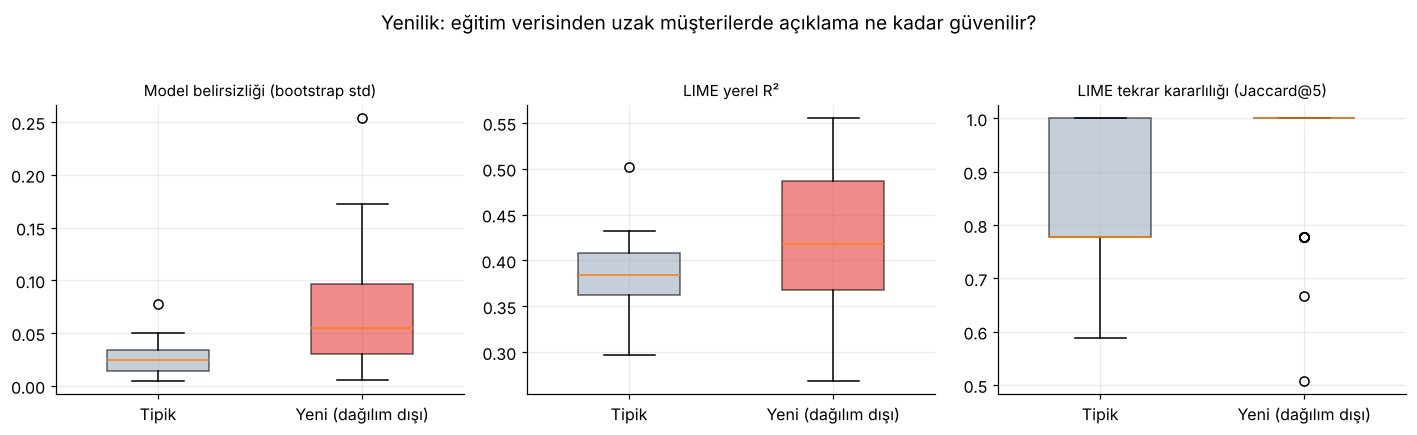

,Tipik (medyan),Yeni (medyan)
Model belirsizliği,0.024,0.055
LIME yerel R²,0.384,0.418
LIME Jaccard@5,0.778,1.000


In [15]:
iso = IsolationForest(n_estimators=300, random_state=RS).fit(Xtr)
yenilik = -iso.score_samples(Xte)
n_y = N_KARARLILIK
yeni_idx = np.argsort(-yenilik)[:n_y]
orta = np.argsort(yenilik)[len(yenilik) // 4: 3 * len(yenilik) // 4]
tipik_idx = rng.choice(orta, n_y, replace=False)


def grup_olc(I):
    X_ = Xte[I]
    bt = np.array([m.predict_proba(X_)[:, 1] for m in boot_modeller]).std(0)
    r2 = [lime_acikla(x)[1] for x in X_]
    jac = [jaccard_top([lime_acikla(x, tohum=t)[0] for t in range(3)]) for x in X_]
    return bt, np.array(r2), np.array(jac)


tip, yen = grup_olc(tipik_idx), grup_olc(yeni_idx)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, k, baslik in zip(axes, range(3), ["Model belirsizliği (bootstrap std)", "LIME yerel R²", "LIME tekrar kararlılığı (Jaccard@5)"]):
    b = ax.boxplot([tip[k], yen[k]], patch_artist=True, widths=0.5)
    ax.set_xticks([1, 2], ["Tipik", "Yeni (dağılım dışı)"])
    for kutu, renk in zip(b["boxes"], ["#A0AEC0", "#E53E3E"]):
        kutu.set_facecolor(renk); kutu.set_alpha(0.6)
    ax.set_title(baslik, fontsize=10)
plt.suptitle("Yenilik: eğitim verisinden uzak müşterilerde açıklama ne kadar güvenilir?", y=1.03)
plt.tight_layout()
sekil_kaydet("07-yenilik")
plt.show()
display(pd.DataFrame({"Tipik (medyan)": [np.median(t) for t in tip], "Yeni (medyan)": [np.median(t) for t in yen]},
                     index=["Model belirsizliği", "LIME yerel R²", "LIME Jaccard@5"]).round(3))

**Yorum.** Bölümün dediği gibi yenilik ve belirlilik birbirine bağlıdır: Verinin seyrek olduğu bölgede model daha belirsizdir.
LIME'ın kendi kalite göstergesi olan yerel R² ise yeni müşterilerde düşmüyor. Yani açıklama, örneğin "yeni" olduğunu kendiliğinden
söylemiyor; tipik bir müşteri için olduğu gibi aynı özgüvenle bir açıklama üretiyor. Sadakat ölçütü iyi görünse bile yeniliği ayrıca
ölçmek gerekir.

## 10. Temsil edicilik

> **Kitabın örneği:** Doğrusal regresyonun ağırlıkları bütün modeli kapsar; Shapley değerleri yalnızca tek bir tahmini.
>
> **Bizim verimizde:** Tek bir müşteri için kurulan yerel açıklamayı o müşteriden uzaklaştıkça diğer müşterilerde deniyor,
> bütün veriyi kapsayan küresel vekil ağaçla karşılaştırıyoruz.

Bir açıklama kaç örneği kapsar? Bir müşteri için kurulan yerel doğrusal açıklamayı, o müşteriden giderek uzaklaşan test örneklerinde
deneriz. Hata büyüdükçe açıklamanın temsil ettiği bölge daralır. Dört açıklamayı karşılaştırıyoruz:

* **Gerçek komşu modeli (başvuru çizgisi):** Müşteriye en yakın %1'lik *gerçek* eğitim örneklerine kurulmuş doğrusal model.
  Yerel bir açıklamanın nasıl davranması gerektiğini gösterir: yakında iyi, uzakta kötü.
* **LIME:** Örneklerini veri dağılımına bakmadan, müşterinin çevresinde geniş bir bölgeden üretir.
* **Küresel vekil ağaç (derinlik 4)** ve **sabit tahmin** (eğitimdeki ortalama olasılık).

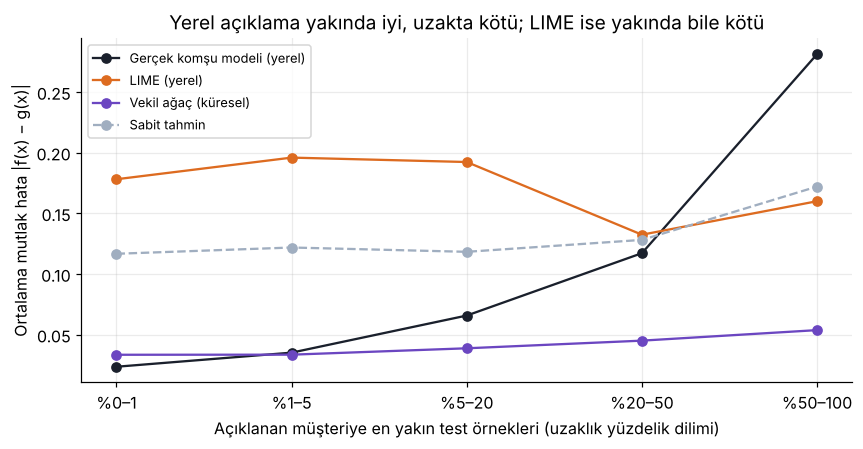

,Gerçek komşu modeli (yerel),LIME (yerel),Vekil ağaç (küresel),Sabit tahmin
%0–1,0.023,0.178,0.033,0.117
%1–5,0.035,0.196,0.033,0.122
%5–20,0.066,0.192,0.039,0.118
%20–50,0.117,0.132,0.045,0.128
%50–100,0.281,0.160,0.054,0.172


In [16]:
vekil4 = DecisionTreeRegressor(max_depth=4, min_samples_leaf=50, random_state=RS).fit(Xtr, f_tr)
dilimler = [(0, 1), (1, 5), (5, 20), (20, 50), (50, 100)]
sonuc = {"Gerçek komşu modeli (yerel)": [], "LIME (yerel)": [], "Vekil ağaç (küresel)": [], "Sabit tahmin": []}
for x0 in Xa[: min(10, N_ORNEK)]:
    w, _, b0, _ = lime_acikla(x0)
    z = (Xte - lime_ac.scaler.mean_) / lime_ac.scaler.scale_       # LIME doğrusal modelini kendi ölçeğinde kurar
    g_lime = b0 + z @ w
    komsu = np.argsort(np.linalg.norm(Xtr - x0, axis=1))[: len(Xtr) // 100]
    g_komsu = Ridge(alpha=1.0).fit(Xtr[komsu], f_tr[komsu]).predict(Xte)
    sira = np.argsort(np.linalg.norm(Xte - x0, axis=1))
    satir = {k: [] for k in sonuc}
    for lo, hi in dilimler:
        I = sira[int(lo / 100 * len(sira)): int(hi / 100 * len(sira))]
        satir["Gerçek komşu modeli (yerel)"].append(np.mean(np.abs(f_te[I] - g_komsu[I])))
        satir["LIME (yerel)"].append(np.mean(np.abs(f_te[I] - g_lime[I])))
        satir["Vekil ağaç (küresel)"].append(np.mean(np.abs(f_te[I] - vekil4.predict(Xte[I]))))
        satir["Sabit tahmin"].append(np.mean(np.abs(f_te[I] - f_tr.mean())))
    for k in sonuc:
        sonuc[k].append(satir[k])

etiket = [f"%{lo}–{hi}" for lo, hi in dilimler]
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, renk, stil in zip(sonuc, ["#1A202C", RENK["LIME"], RENK["Vekil ağaç"], "#A0AEC0"], ["o-", "o-", "o-", "o--"]):
    ax.plot(etiket, np.median(sonuc[k], 0), stil, color=renk, label=k)
ax.set_xlabel("Açıklanan müşteriye en yakın test örnekleri (uzaklık yüzdelik dilimi)")
ax.set_ylabel("Ortalama mutlak hata |f(x) − g(x)|")
ax.set_title("Yerel açıklama yakında iyi, uzakta kötü; LIME ise yakında bile kötü")
ax.legend(fontsize=8.5)
plt.tight_layout()
sekil_kaydet("08-temsil-edicilik")
plt.show()
display(pd.DataFrame({k: np.median(v, 0) for k, v in sonuc.items()}, index=etiket).round(3))

**Yorum.** Gerçek komşularla kurulan yerel model, bölümdeki "temsil edicilik" kavramını açıkça gösteriyor: Açıklanan müşterinin
yakınında kara kutuya en iyi yaklaşan odur, uzaklaştıkça hatası büyür. Bu, tek bir müşteriyi temsil eden bir açıklamanın beklenen
davranışıdır. Küresel vekil ağaç her yerde aynı orta düzey hatayı verir, yani bütün veriyi temsil eder. LIME'ın yerel modeli ise
müşterinin en yakın komşularında bile sabit bir tahminden daha kötü. Örnekleri gerçek veri dağılımından değil, geniş ve yapay bir
bölgeden geldiği için LIME'ın açıklaması ne yereli ne de bütünü temsil ediyor. Bu, dersin sızma testi bakışına uyan bir zafiyettir:
Varsayılan ayarlarla kullanılan LIME, yüksek boyutlu tablo verisinde "yerel" adını hak etmeyebilir.

## 11. Karne: yöntemleri özelliklere göre yan yana koymak

Tek bir "en iyi" yöntem yoktur. Her yöntem bazı özelliklerde güçlü, bazılarında zayıftır. Bölüm 32'nin değerlendirme
çerçevesinin pratik çıktısı, kullanım amacına göre hangi özelliklerin önemli olduğuna karar verip yöntemleri bu özelliklere göre seçmektir.

In [17]:
vekil_d3 = vekil.set_index("Derinlik").loc[3]
karne = pd.DataFrame({
    "Süre (ms/açıklama)": [1000 * sure["LIME"], 1000 * sure["KernelSHAP"], 1000 * sure["TreeSHAP"], 0.0],
    "Sadakat": [f"yerel R² {np.median(lime_k[d]):.2f}; x'te hata {np.median(lime_x_hatasi):.2f}", f"toplamsal (hata {hata_ks:.0e})",
                f"toplamsal (hata {hata_ts:.0e})", f"küresel R² {vekil_d3['Sadakat R²']:.2f}"],
    "Tekrar kararlılığı (Jaccard@5)": [np.median(tekrar["LIME"]), np.median(tekrar["KernelSHAP"]), np.median(tekrar["TreeSHAP"]), 1.0],
    "Girdi kararlılığı (Jaccard@5)": [np.median(girdi["LIME"]), np.median(girdi["KernelSHAP"]),
                                       np.median(girdi["TreeSHAP"]), np.nan],
    "İlk 3'ün payı": [np.median(onem_derecesi["LIME"]), np.median(onem_derecesi["KernelSHAP"]),
                      np.median(onem_derecesi["TreeSHAP"]), np.nan],
    "Boyut": [f"{d} ağırlık", f"{d} katkı", f"{d} katkı", f"{int(vekil_d3['Yaprak'])} yaprak"],
    "Temsil": ["tek örnek (yerel)", "tek örnek", "tek örnek", "tüm veri (küresel)"],
    "Yarı saydamlık": ["yok", "yok", "yüksek", "yok"],
    "Taşınabilirlik": ["her model", "her model", "ağaçlar", "her model"],
}, index=["LIME", "KernelSHAP", "TreeSHAP", "Vekil ağaç (d=3)"]).round(2)
display(karne)

,Süre (ms/açıklama),Sadakat,Tekrar kararlılığı (Jaccard@5),Girdi kararlılığı (Jaccard@5),İlk 3'ün payı,Boyut,Temsil,Yarı saydamlık,Taşınabilirlik
LIME,16.23,yerel R² 0.39; x'te hata 0.17,0.84,0.97,0.42,23 ağırlık,tek örnek (yerel),yok,her model
KernelSHAP,65.63,toplamsal (hata 2e-16),1.00,0.72,0.53,23 katkı,tek örnek,yok,her model
TreeSHAP,1.34,toplamsal (hata 1e-08),1.00,0.76,0.46,23 katkı,tek örnek,yüksek,ağaçlar
Vekil ağaç (d=3),0.00,küresel R² 0.85,1.00,NaN,NaN,8 yaprak,tüm veri (küresel),yok,her model


## 12. Değerlendirme düzeyleri açısından bu defter

> **Kitabın örnekleri:** Uygulama düzeyinde radyologlar kırık tespit yazılımını kendi işlerinde dener; insan düzeyinde uzman
> olmayan katılımcılar birkaç açıklamadan en iyisini seçer; işlev düzeyinde ağacın derinliği gibi vekil ölçütler kullanılır.

Buradaki tüm ölçütler **işlev düzeyindedir**: Hiçbiri insan gerektirmez, hepsi ucuz ve tekrarlanabilir. Ama hiçbiri bir kredi
uzmanının ya da başvurunun reddedildiği müşterinin açıklamayı *anlayıp* doğru karar verip vermediğini ölçmez. Bu soruyu yanıtlamak
için **insan düzeyinde** (örneğin "bu açıklamaya bakarak modelin kararını tahmin edin" deneyi) ya da **uygulama düzeyinde**
(gerçek kredi sürecine yerleştirip test etme) değerlendirme gerekir. Bölüm 32'nin ana mesajı da budur: Vekil ölçütler gereklidir ama
yeterli değildir.

## 13. Etkileşimli sayfa için veriler

Bu defterin yanında, kodu açmadan herkesin tıklayarak kullanabileceği bir etkileşimli sayfa var (`etkilesimli/index.html`).
Sayfadaki bütün sayılar bu defterden gelir: Aşağıdaki hücre, sayfanın kullandığı sonuçları `etkilesimli/veri.json` dosyasına
yazar ve sayfanın içindeki gömülü kopyayı da günceller. Sayfadaki müşteriler, SVM örneğinin de hesaplandığı müşteriler
arasından temerrüt olasılığına göre yayılarak seçilir.

In [18]:
import json

ay = lambda i: "son ay" if i == 1 else f"{i} ay önce"  # tahmin edilen aydan (ekim) geriye: PAY_1 eylül, PAY_3 temmuz
OZN_TR = {"LIMIT_BAL": "Kredi limiti", "SEX": "Cinsiyet", "EDUCATION": "Eğitim düzeyi", "MARRIAGE": "Medeni durum", "AGE": "Yaş",
          **{f"PAY_{i}": f"Ödeme durumu ({ay(i)})" for i in range(1, 7)},
          **{f"BILL_AMT{i}": f"Fatura tutarı ({ay(i)})" for i in range(1, 7)},
          **{f"PAY_AMT{i}": f"Ödenen tutar ({ay(i)})" for i in range(1, 7)}}


def temizle(o):
    """JSON'a uygun hâle getirir: numpy sayıları Python sayısına, NaN null'a döner; ondalıklar 4 basamağa yuvarlanır."""
    if isinstance(o, dict):
        return {str(k): temizle(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, np.ndarray)):
        return [temizle(v) for v in o]
    if isinstance(o, (bool, np.bool_)):
        return bool(o)
    if isinstance(o, (int, np.integer)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return round(float(o), 4) if np.isfinite(o) else None
    return o


p_xs = f(Xs)
sira_p = np.argsort(p_xs)
sayfa_idx = sorted({int(sira_p[k]) for k in np.linspace(0, len(sira_p) - 1, 7).round().astype(int)} | {i_sl})
ham_x = olcek.inverse_transform(Xa)
tum_modeller = {**modeller, "SVM": svm}
ozellik = lambda i: {o: float(ham_x[i, j]) for j, o in enumerate(OZN)}
lime_tam = {i: lime_acikla(Xa[i]) for i in sayfa_idx}  # ağırlıklar, yerel R², sabit terim, yerel modelin x'teki tahmini
musteriler = [{
    "ad": f"Müşteri {k}",
    "gercek": int(np.asarray(y_te)[idx[i]]),  # 1: gerçekte temerrüde düştü
    "ozellikler": ozellik(i),
    "tahmin": {ad: m.predict_proba(Xa[i:i + 1])[0, 1] for ad, m in tum_modeller.items()},
    "aciklama": {"LIME": A_lime[i], "KernelSHAP": A_ks[i], "TreeSHAP": A_ts[i]},
    "lime_yerel": {"r2": lime_tam[i][1], "tahmin": lime_tam[i][3]},
    "lime_tohumlar": [lime_acikla(Xa[i], tohum=t)[0] for t in range(8)],
    "model_aciklamalari": {**{ad: A_model[ad][i] for ad in adlar}, "SVM": A_svm[i]},
} for k, i in enumerate(sayfa_idx, 1)]

veri = {
    "veri": {"musteri": len(df), "oznitelik": d, "temerrut_orani": y.mean(), "hizli_mod": HIZLI},
    "oznitelikler": [{"ad": o, "tr": OZN_TR[o]} for o in OZN],
    "basarim": {**{ad: {"auc": r["Test AUC"], "dogruluk": r["Doğruluk"]} for ad, r in basarim.iterrows()},
                "SVM": {"auc": roc_auc_score(y_te, p_svm), "dogruluk": accuracy_score(y_te, p_svm > 0.5)}},
    "sure_ms": {k: 1000 * v for k, v in sure.items()},
    "taban": {"KernelSHAP": float(np.ravel(ks_gbm.expected_value)[0]), "TreeSHAP": float(np.ravel(ts_gbm.expected_value)[0])},
    "musteriler": musteriler,
    "sadakat": {"vekil": vekil.to_dict("records"), "kara_kutu_auc": auc_kk,
                "lime_k": {str(k): [np.median(v), np.percentile(v, 25), np.percentile(v, 75)] for k, v in lime_k.items()},
                "lime_x_hatasi": {"medyan": np.median(lime_x_hatasi), "en_buyuk": lime_x_hatasi.max()},
                "toplamsallik": {"TreeSHAP": f"{hata_ts:.1e}", "KernelSHAP": f"{hata_ks:.1e}"}},
    "kararlilik": {"tekrar": tekrar, "girdi": girdi, "tahmin_degisimi": np.mean(tahmin_degisimi)},
    "tutarlilik": {"modeller": adlar, "tahmin_kor": tahmin_kor, "aciklama_kor": aciklama_kor,
                   "dayanak": {ad: {o: onem.loc[o, ad] for o in ilk} for ad in adlar},
                   "svm_lojistik": {"r": r_sl, "rho_medyan": np.median(rho_sl), "jaccard_medyan": np.median(jac_sl),
                                    "ornek_musteri": f"Müşteri {sayfa_idx.index(i_sl) + 1}"}},
    "belirlilik": {"rho": rho_b,
                   "dagilim": np.column_stack([model_belirsizligi, aciklama_belirsizligi, boot_tahmin.mean(0)]),
                   "ornek": {ad: {"ana_tahmin": p_ana[ii], "bootstrap": boot_tahmin[:, ii],
                                  "atif_ort": boot_aciklama[:, ii].mean(0), "atif_std": boot_aciklama[:, ii].std(0),
                                  "ozellikler": ozellik(ii)} for ad, ii in [("A", iA), ("B", iB)]}},
    "onem_derecesi": {"ilk3_payi": {k: np.median(v) for k, v in onem_derecesi.items()},
                      "kural": {"kosullar": kosullar, "tahmin": kural_tahmini,
                                "kosul_onemi": kosul_onemi.rename(columns={"Kaldırılan koşul": "kaldirilan",
                                                                           "Kapsanan müşteri": "kapsam",
                                                                           "Ortalama tahmin": "ort_tahmin"}).to_dict("records")}},
    "yenilik": {grup: {"model_belirsizligi": g[0], "lime_r2": g[1], "lime_jaccard": g[2]}
                for grup, g in [("tipik", tip), ("yeni", yen)]},
    "temsil": {"dilimler": etiket, "egriler": {k: np.median(v, 0) for k, v in sonuc.items()}},
    "karne": karne.reset_index().rename(columns={"index": "Yöntem"}).to_dict("records"),
}
SAYFA_KLASORU = Path("etkilesimli")
SAYFA_KLASORU.mkdir(exist_ok=True)
json_yolu = SAYFA_KLASORU / "veri.json"
json_yolu.write_text(json.dumps(temizle(veri), ensure_ascii=False, indent=1), encoding="utf-8")
print(f"{json_yolu} yazıldı: {len(musteriler)} müşteri, {json_yolu.stat().st_size / 1024:.0f} KB")

# Sayfa, çift tıklayınca çevrimdışı da açılabilsin diye bu verinin gömülü bir kopyasını taşır; kopyayı burada güncelliyoruz.
sayfa = SAYFA_KLASORU / "index.html"
if sayfa.exists():
    html = sayfa.read_text(encoding="utf-8")
    bas = '<script type="application/json" id="veri">'
    i = html.index(bas) + len(bas)
    j = html.index("</script>", i)
    sayfa.write_text(html[:i] + json.dumps(temizle(veri), ensure_ascii=False) + html[j:], encoding="utf-8")
    print(f"{sayfa} içindeki veri kopyası güncellendi")

etkilesimli/veri.json yazıldı: 8 müşteri, 70 KB
